# When does uncertainty sampling start to pay off?

**Active-learning budget study: the full pipeline in one notebook.**

Uncertainty sampling (least confidence, margin, entropy) is known to *lose* to random sampling when the labelled set is
tiny (the "cold start" problem; Hacohen et al. 2022, *Active Learning on a Budget*) and to *win* once enough labels are
available. This notebook asks **what sets the budget where the switch happens**, and in particular how it depends on
the structure of the data: the number of modes (classes × clusters per class), how well separated the modes are, and
how imbalanced the classes are.

### Hypotheses

| | |
|---|---|
| **H1** | For every uncertainty score there is a crossover budget $b^*$: below it random/BADGE win, above it the uncertainty score wins. |
| **H2** | $b^*$ grows with the number of modes $K = C \times M$. |

The practical output is a map of the best strategy per (setting, budget).

### Notebook outline

1. Setup and configuration (quick vs. full mode)
2. Synthetic data: a Gaussian-mixture generator with controlled separation
3. Query strategies (the six methods from the course notebooks)
4. The active-learning loop (paired design, cached results)
5. Experiments: core grid + separation and class-imbalance sweeps
6. Analysis
   * 6.1 Learning curves
   * 6.2 AULC at low and high budgets
   * 6.3 Crossover budget $b^*$ with bootstrap CIs
   * 6.4 Phase diagram
   * 6.5 H2: $b^*$ vs. $K$
   * 6.6 Best-strategy map
   * 6.7 Separation and class-imbalance sweeps
   * 6.8 Sanity check: the binary case
7. Summary

## 1. Setup

Only numpy / scipy / scikit-learn / matplotlib / joblib are needed (all in the `ucph` conda env).

In [1]:
import hashlib
import json
import time
import zlib
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.ticker import LogLocator, NullFormatter, ScalarFormatter
from scipy.spatial.distance import pdist
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics.pairwise import euclidean_distances

### Configuration

`MODE = "quick"` runs a reduced version (few seeds, budget ≤ 300) in a few minutes, which is enough to check that
everything works and to see the qualitative picture. Switch to `MODE = "full"` for the numbers that go into the report
(20–30 seeds, budget up to 1000; roughly 1–2 h on a 10-core laptop).

Every single run is cached to `results/` as one `.npz` file per (setting, strategy, seed), so re-running the notebook
only computes what is missing, and an interrupted full run can be resumed.

In [2]:
MODE = "quick"  # "quick" or "full"

CFG = {
    "quick": dict(n_seeds=5, max_budget=300, n_boot=300),
    "full": dict(n_seeds=25, max_budget=1000, n_boot=2000),
}[MODE]

SEEDS = list(range(CFG["n_seeds"]))
MAX_BUDGET = CFG["max_budget"]
INIT = 10          # size of the random initial labelled set
SMALL_BATCH = 5    # batch size while the budget is below SMALL_UNTIL ...
SMALL_UNTIL = 50
BATCH = 10         # ... and afterwards
B_REF = 100        # split between the "low" and "high" budget regimes for AULC and the best-strategy summary
N_JOBS = -1       # parallel runs (each random forest itself uses one core)

RESULTS_DIR = Path("results").resolve()
FIG_DIR = Path("figures").resolve()
FIG_DIR.mkdir(exist_ok=True)

STRATEGY_NAMES = ["random", "least_conf", "margin", "entropy", "badge", "farthest"]
UNCERTAINTY = ["least_conf", "margin", "entropy"]

print(f"mode={MODE}, seeds={len(SEEDS)}, max budget={MAX_BUDGET}")

mode=quick, seeds=5, max budget=300


Plot styling: one fixed colour per strategy used in every figure. Random is the grey dashed reference line; the three
uncertainty scores get the first three categorical colours, and the two diversity-flavoured methods also get their own
line style so they stay distinguishable without colour.

In [3]:
STYLE = {
    "random":     dict(color="#898781", ls="--", label="Random"),
    "least_conf": dict(color="#2a78d6", ls="-",  label="Least confidence"),
    "margin":     dict(color="#eb6834", ls="-",  label="Margin"),
    "entropy":    dict(color="#1baf7a", ls="-",  label="Entropy"),
    "badge":      dict(color="#eda100", ls="-.", label="BADGE"),
    "farthest":   dict(color="#e87ba4", ls=":",  label="Farthest-first"),
}
# diverging map for "strategy minus random": red = worse than random, grey = equal, blue = better
DIVERGING = LinearSegmentedColormap.from_list("rgb_div", ["#e34948", "#f0efec", "#2a78d6"])
# sequential steps (light -> dark blue) for the levels of a sweep
SWEEP_COLORS = ["#86b6ef", "#2a78d6", "#104281"]

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "font.size": 9,
})


def log_axis(ax, which="x"):
    # log scale with plain tick labels at 1-2-5 steps (10, 20, 50, 100, ...)
    getattr(ax, f"set_{which}scale")("log")
    axis = getattr(ax, f"{which}axis")
    axis.set_major_locator(LogLocator(subs=(1, 2, 5)))
    axis.set_major_formatter(ScalarFormatter())
    axis.set_minor_formatter(NullFormatter())


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=200)

## 2. Synthetic data: Gaussian mixture with controlled separation

In a preliminary experiment with scikit-learn's `make_classification`, increasing the number of classes or clusters
also made the task much harder (accuracy at 300 labels fell from 0.88 to 0.52), so the number of modes $K$ was **confounded with
difficulty**. We therefore write our own generator:

* $C$ classes, $M$ modes per class, so $K = C \cdot M$ isotropic Gaussian modes in $\mathbb{R}^d$ with std $\sigma$.
* Mode centres are placed by **rejection sampling in a box**: a candidate is accepted only if it is at least
  `sep · σ` away from every centre already placed. The box starts tight and grows only when the centres do not fit,
  so the packing is fairly dense. Finally all centres are rescaled so that the **minimum inter-mode distance is exactly
  `sep · σ`**. This keeps the closest pair of modes equally hard to tell apart whatever $K$ is.
* Optional factors: class imbalance (long-tail class weights), unequal mode sizes within a class, label noise
  (flipped in the pool only; the test set stays clean).

In [4]:
def place_centers(K, d, min_dist, rng, max_tries=2000):
    # start with a box that would fit K points at spacing min_dist, grow it when it is too small
    half = 0.5 * min_dist * K ** (1 / d)
    while True:
        centers, tries = [], 0
        while len(centers) < K and tries < max_tries:
            c = rng.uniform(-half, half, d)
            if not centers or np.linalg.norm(np.asarray(centers) - c, axis=1).min() >= min_dist:
                centers.append(c)
                tries = 0
            else:
                tries += 1
        if len(centers) == K:
            break
        half *= 1.1
    centers = np.asarray(centers)
    return centers * (min_dist / pdist(centers).min())  # min pairwise distance is now exactly min_dist


def long_tail(n, ratio):
    # geometric weights with w[0] / w[-1] = ratio, summing to one
    w = float(ratio) ** (-np.arange(n) / max(n - 1, 1))
    return w / w.sum()


def make_mixture(C, M, d, sep, rng, sigma=1.0, imbalance=1.0, mode_skew=1.0):
    K = C * M
    centers = place_centers(K, d, sep * sigma, rng)
    mode_class = np.repeat(np.arange(C), M)  # centres are placed in random order, so this assignment is random
    weights = np.repeat(long_tail(C, imbalance), M) * np.tile(long_tail(M, mode_skew), C)
    return dict(centers=centers, mode_class=mode_class, weights=weights / weights.sum(), sigma=sigma, C=C, K=K)


def sample_mixture(mix, n, rng, label_noise=0.0):
    mode_id = rng.choice(mix["K"], size=n, p=mix["weights"])
    X = mix["centers"][mode_id] + mix["sigma"] * rng.standard_normal((n, mix["centers"].shape[1]))
    y = mix["mode_class"][mode_id].copy()
    if label_noise > 0:
        flip = rng.random(n) < label_noise
        y[flip] = (y[flip] + rng.integers(1, mix["C"], flip.sum())) % mix["C"]  # move to a different class
    return X, y

### Settings

A `Setting` bundles the data parameters of one experimental condition plus the maximum budget. The initial set size
and the batch schedule are fixed for all experiments (see the configuration above). Its `name` (readable prefix + hash
of all fields) is the cache key for the results.

**Seeding and the paired design.** Within a seed, *all strategies see the same pool, the same test set and the same
initial labelled set*, so strategy differences can be analysed as paired differences (much less noisy). The data seed
depends only on the data fields, not on the maximum budget. We derive seeds with `zlib.crc32` because Python's
`hash()` of a string changes between processes.

In [5]:
@dataclass(frozen=True)
class Setting:
    # data
    C: int = 3                # classes
    M: int = 2                # modes (clusters) per class
    d: int = 10               # dimension
    sep: float = 4.0          # minimum inter-mode distance in units of sigma
    sigma: float = 1.0
    imbalance: float = 1.0    # largest / smallest class weight
    mode_skew: float = 1.0    # largest / smallest mode weight within a class
    label_noise: float = 0.0
    n_pool: int = 3000
    n_test: int = 1000
    max_budget: int = 1000

    DATA_FIELDS = ("C", "M", "d", "sep", "sigma", "imbalance", "mode_skew", "label_noise", "n_pool", "n_test")

    @property
    def K(self):
        return self.C * self.M

    def data_key(self):
        return {k: getattr(self, k) for k in self.DATA_FIELDS}

    @property
    def name(self):
        h = hashlib.md5(json.dumps(asdict(self), sort_keys=True).encode()).hexdigest()[:8]
        return f"C{self.C}_M{self.M}_d{self.d}_sep{self.sep:g}_imb{self.imbalance:g}_{h}"

    @property
    def label(self):
        return f"{self.C}×{self.M} (K={self.K})"


def seed_for(*parts):
    return zlib.crc32(json.dumps(parts, sort_keys=True).encode())


def make_data(s, seed):
    rng = np.random.default_rng([seed, seed_for(s.data_key())])
    mix = make_mixture(s.C, s.M, s.d, s.sep, rng, s.sigma, s.imbalance, s.mode_skew)
    pool = sample_mixture(mix, s.n_pool, rng, s.label_noise)
    test = sample_mixture(mix, s.n_test, rng)
    return mix, pool, test

### What the data looks like

Two-dimensional examples with $C = 3$ classes and an increasing number of modes per class. The minimum distance between
any two mode centres (× markers) is the same in all three panels; only the number of modes changes.

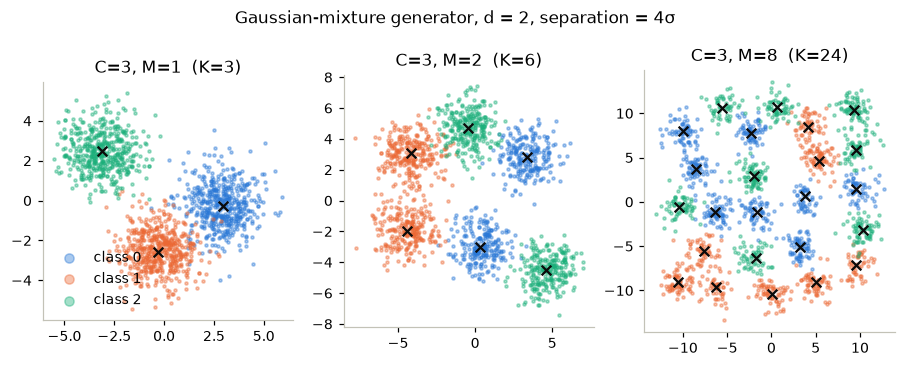

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3))
for ax, M in zip(axes, (1, 2, 8)):
    mix, (X, y), _ = make_data(Setting(C=3, M=M, d=2, n_pool=1500), seed=0)
    for c in range(3):
        color = STYLE[UNCERTAINTY[c]]["color"]
        ax.scatter(*X[y == c].T, s=4, alpha=0.4, color=color, label=f"class {c}", rasterized=True)
        ax.scatter(*mix["centers"][mix["mode_class"] == c].T, marker="x", s=40, color="#0b0b0b", linewidths=1.5)
    ax.set_title(f"C=3, M={M}  (K={3 * M})")
    ax.set_aspect("equal")
    ax.grid(False)
axes[0].legend(markerscale=3, loc="lower left")
fig.suptitle("Gaussian-mixture generator, d = 2, separation = 4σ", y=1.02)
savefig(fig, "data_examples")
plt.show()

### Difficulty check

The point of the custom generator is that $K$ should not change how hard the task is. We check this with two
"ceilings" per core-grid setting (d = 10):

* **Nearest-centre oracle**: classify each test point by the class of its closest true mode centre. This is
  (close to) the Bayes-optimal classifier for equally weighted isotropic modes.
* **RF on the full pool**: the random forest trained on all 3000 pool labels, i.e. the accuracy active learning is
  converging to.

If the curves are roughly flat in $K$, differences in $b^*$ between settings cannot be blamed on difficulty.

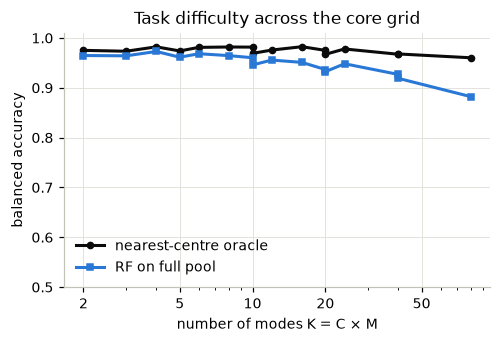

| setting | oracle | RF full pool |
|---|---|---|
| 2×1 (K=2) | 0.975 | 0.965 |
| 2×2 (K=4) | 0.982 | 0.973 |
| 2×4 (K=8) | 0.982 | 0.965 |
| 2×8 (K=16) | 0.983 | 0.951 |
| 3×1 (K=3) | 0.973 | 0.964 |
| 3×2 (K=6) | 0.981 | 0.968 |
| 3×4 (K=12) | 0.976 | 0.956 |
| 3×8 (K=24) | 0.978 | 0.948 |
| 5×1 (K=5) | 0.974 | 0.961 |
| 5×2 (K=10) | 0.982 | 0.960 |
| 5×4 (K=20) | 0.975 | 0.937 |
| 5×8 (K=40) | 0.967 | 0.927 |
| 10×1 (K=10) | 0.969 | 0.946 |
| 10×2 (K=20) | 0.967 | 0.932 |
| 10×4 (K=40) | 0.968 | 0.919 |
| 10×8 (K=80) | 0.960 | 0.882 |

In [7]:
def ceilings(s, seed):
    mix, (Xp, yp), (Xt, yt) = make_data(s, seed)
    nearest = mix["mode_class"][euclidean_distances(Xt, mix["centers"]).argmin(1)]
    rf = RandomForestClassifier(50, random_state=seed, n_jobs=1).fit(Xp, yp)
    return balanced_accuracy_score(yt, nearest), balanced_accuracy_score(yt, rf.predict(Xt))


grid = [Setting(C=C, M=M) for C in (2, 3, 5, 10) for M in (1, 2, 4, 8)]
ceil = Parallel(n_jobs=N_JOBS)(delayed(ceilings)(s, seed) for s in grid for seed in range(3))
ceil = np.array(ceil).reshape(len(grid), 3, 2).mean(1)

fig, ax = plt.subplots(figsize=(5, 3))
Ks = np.array([s.K for s in grid])
order = np.argsort(Ks, kind="stable")
ax.plot(Ks[order], ceil[order, 0], "o-", color="#0b0b0b", ms=4, label="nearest-centre oracle")
ax.plot(Ks[order], ceil[order, 1], "s-", color=STYLE["least_conf"]["color"], ms=4, label="RF on full pool")
log_axis(ax)
ax.set_xlabel("number of modes K = C × M")
ax.set_ylabel("balanced accuracy")
ax.set_ylim(0.5, 1.01)
ax.legend()
ax.set_title("Task difficulty across the core grid")
savefig(fig, "difficulty_check")
plt.show()

display(Markdown("| setting | oracle | RF full pool |\n|---|---|---|\n" + "\n".join(
    f"| {s.label} | {a:.3f} | {b:.3f} |" for s, (a, b) in zip(grid, ceil))))

Difficulty is nearly constant up to $K \approx 20$ and drops somewhat for the largest grids (more modes means more
close neighbours, even though the *closest* pair is fixed). That is a much milder confound than with `make_classification`, and the
table above is worth reporting next to the main results.

## 3. Query strategies

These are the six methods from the course notebooks. Each strategy has the same
signature: it gets the current model, the pool `X`, the labelled indices `L`, the unlabelled indices `U`, the batch size
`k`, a random generator and the number of classes, and returns **positions into `U`** of the `k` points to label.

* **Random**: uniform over the unlabelled pool.
* **Least confidence**: largest $1 - \max_c p(c \mid x)$.
* **Margin**: smallest gap between the two most probable classes.
* **Entropy**: largest predictive entropy.
* **BADGE (simplified)**: gradient embedding of a linear soft-max head on the raw features,
  $g(x) = (p(x) - e_{\hat y}) \otimes [x, 1]$, followed by k-means++ seeding. It mixes uncertainty (embedding norm)
  with diversity (k-means++ spreads out the picks).
* **Farthest-first (core-set style)**: greedily pick the unlabelled point farthest from all labelled and already
  picked points.

Two implementation details matter:

* **Random tie-breaking.** Random-forest probabilities are multiples of 1/50, so many pool points share exactly the same
  uncertainty score. `np.argsort` would then pick ties by index order, which is an arbitrary but *systematic* choice.
  We round the scores (to remove floating-point noise) and break ties uniformly at random.
* **Missing classes.** With a random 10-point initial set some classes may not be labelled yet. `predict_proba_full`
  puts the model's probabilities into a full $C$-column matrix so every strategy sees all classes.

In [8]:
def predict_proba_full(model, X, n_classes):
    P = np.zeros((len(X), n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P


def top_k(score, k, rng):
    # indices of the k largest scores, exact ties broken uniformly at random
    score = np.round(score, 10)
    return np.lexsort((rng.random(len(score)), -score))[:k]


def random_sampling(model, X, L, U, k, rng, n_classes):
    return rng.choice(len(U), size=k, replace=False)


def least_confidence(model, X, L, U, k, rng, n_classes):
    P = predict_proba_full(model, X[U], n_classes)
    return top_k(1 - P.max(1), k, rng)


def margin(model, X, L, U, k, rng, n_classes):
    P = np.sort(predict_proba_full(model, X[U], n_classes), axis=1)
    return top_k(-(P[:, -1] - P[:, -2]), k, rng)


def entropy(model, X, L, U, k, rng, n_classes):
    P = np.clip(predict_proba_full(model, X[U], n_classes), 1e-12, 1)
    return top_k(-(P * np.log(P)).sum(1), k, rng)


def badge(model, X, L, U, k, rng, n_classes):
    P = predict_proba_full(model, X[U], n_classes)
    Xa = np.column_stack([X[U], np.ones(len(U))])
    R = P.copy()
    R[np.arange(len(U)), P.argmax(1)] -= 1                      # gradient w.r.t. the logits at the predicted label
    E = (R[:, :, None] * Xa[:, None, :]).reshape(len(U), -1)    # gradient embedding
    sel = [int(np.argmax((E ** 2).sum(1)))]
    dist = ((E - E[sel[0]]) ** 2).sum(1)
    while len(sel) < k:                                          # k-means++ seeding (D^2 sampling)
        q = dist.copy()
        q[sel] = 0
        if q.sum() > 0:
            nxt = int(rng.choice(len(U), p=q / q.sum()))
        else:                                                    # all embeddings identical: fall back to random
            nxt = int(rng.choice(np.setdiff1d(np.arange(len(U)), sel)))
        sel.append(nxt)
        dist = np.minimum(dist, ((E - E[nxt]) ** 2).sum(1))
    return np.array(sel)


def farthest_first(model, X, L, U, k, rng, n_classes):
    dist = euclidean_distances(X[U], X[L]).min(1)
    sel = []
    for _ in range(k):
        i = int(np.argmax(dist))
        sel.append(i)
        dist = np.minimum(dist, euclidean_distances(X[U], X[U][i : i + 1]).ravel())
        dist[sel] = -1
    return np.array(sel)


STRATEGIES = dict(
    random=random_sampling, least_conf=least_confidence, margin=margin,
    entropy=entropy, badge=badge, farthest=farthest_first,
)

## 4. The active-learning loop

* **Initial set: random, not stratified.** Stratifying would use label information we do not have and would hide
  exactly the cold-start effect we want to measure. With 10 random points some classes may be missing.
* **Fixed batch schedule:** an initial set of `INIT` = 10, batches of 5 until 50 labels, then batches of 10 up to
  the maximum budget. The same schedule is used in every experiment.
* **Classifier:** `RandomForestClassifier(50 trees)` as in the course notebooks, refitted from scratch every round.
* **Recorded per budget:** test balanced accuracy.

In [9]:
def budget_schedule(max_budget):
    b, out = INIT, [INIT]
    while b < max_budget:
        b = min(b + (SMALL_BATCH if b < SMALL_UNTIL else BATCH), max_budget)
        out.append(b)
    return np.array(out)


def fit_model(X, y, seed):
    return RandomForestClassifier(n_estimators=50, random_state=seed, n_jobs=1).fit(X, y)


def run_al(s, strategy, seed):
    _, (Xp, yp), (Xt, yt) = make_data(s, seed)
    init_rng = np.random.default_rng([seed, seed_for(s.data_key()), 1])   # same initial set for every strategy
    query_rng = np.random.default_rng([seed, 2])
    labeled = np.zeros(len(Xp), dtype=bool)
    labeled[init_rng.choice(len(Xp), INIT, replace=False)] = True

    budgets = budget_schedule(s.max_budget)
    acc = []
    model = None
    for b in budgets:
        if model is not None:
            L, U = np.flatnonzero(labeled), np.flatnonzero(~labeled)
            pos = STRATEGIES[strategy](model, Xp, L, U, b - len(L), query_rng, s.C)
            labeled[U[pos]] = True
        L = np.flatnonzero(labeled)
        model = fit_model(Xp[L], yp[L], seed)
        acc.append(balanced_accuracy_score(yt, model.predict(Xt)))
    return dict(budgets=budgets, acc=np.array(acc))

Caching and parallel execution: one job per (setting, strategy, seed); jobs whose result file already exists are
skipped. Each setting's folder also gets a `setting.json` so the results are self-describing.

In [10]:
def result_path(s, strategy, seed):
    return RESULTS_DIR / s.name / f"{strategy}_seed{seed:03d}.npz"


def run_and_save(s, strategy, seed):
    np.savez(result_path(s, strategy, seed), **run_al(s, strategy, seed))


def run_experiments(settings, strategies=STRATEGY_NAMES, seeds=SEEDS):
    settings = list(dict.fromkeys(settings))  # drop duplicates, keep order
    for s in settings:
        (RESULTS_DIR / s.name).mkdir(parents=True, exist_ok=True)
        (RESULTS_DIR / s.name / "setting.json").write_text(json.dumps(asdict(s), indent=1))
    jobs = [(s, st, sd) for s in settings for st in strategies for sd in seeds
            if not result_path(s, st, sd).exists()]
    print(f"{len(settings)} settings, {len(jobs)} runs to compute "
          f"({len(settings) * len(strategies) * len(seeds) - len(jobs)} cached)")
    t0 = time.time()
    Parallel(n_jobs=N_JOBS, verbose=0)(delayed(run_and_save)(*job) for job in jobs)
    print(f"finished in {time.time() - t0:.0f} s")


def load(s, strategies=STRATEGY_NAMES, seeds=SEEDS):
    # returns {"budgets": (B,), "acc": {strategy: (n_seeds, B)}}
    out = {"acc": {}}
    for st in strategies:
        runs = [np.load(result_path(s, st, sd)) for sd in seeds]
        out["acc"][st] = np.stack([r["acc"] for r in runs])
    out["budgets"] = runs[0]["budgets"]
    return out

Quick smoke test on the reference setting before launching everything: one run per strategy at a small budget.

In [11]:
t0 = time.time()
smoke = Setting(max_budget=60)
for st in STRATEGY_NAMES:
    r = run_al(smoke, st, seed=0)
    print(f"{st:11s} acc at budgets {r['budgets'][[0, 4, -1]]}: {np.round(r['acc'][[0, 4, -1]], 3)}")
print("budgets:", budget_schedule(smoke.max_budget), f"  ({time.time() - t0:.1f} s)")

random      acc at budgets [10 30 60]: [0.703 0.754 0.902]


least_conf  acc at budgets [10 30 60]: [0.703 0.872 0.946]


margin      acc at budgets [10 30 60]: [0.703 0.866 0.93 ]


entropy     acc at budgets [10 30 60]: [0.703 0.872 0.933]


badge       acc at budgets [10 30 60]: [0.703 0.831 0.916]


farthest    acc at budgets [10 30 60]: [0.703 0.852 0.896]
budgets: [10 15 20 25 30 35 40 45 50 60]   (1.7 s)


## 5. Experiments

**Core grid:** $C \in \{2, 3, 5, 10\} \times M \in \{1, 2, 4, 8\}$, so $K$ ranges from 2 to 80, with fixed separation
(4σ), $d = 10$, balanced classes.

**Sweeps** around the reference setting $C = 3, M = 2$ (each sweep changes one thing):

| factor | values | question |
|---|---|---|
| separation | 3, 4, 5 σ | does a harder task move $b^*$? |
| class imbalance | 1, 5, 20 | rare classes get few random labels; does uncertainty sampling profit earlier? |

In [12]:
REF = Setting(C=3, M=2, max_budget=MAX_BUDGET)
CORE = [replace(REF, C=C, M=M) for C in (2, 3, 5, 10) for M in (1, 2, 4, 8)]
REPRESENTATIVE = [replace(REF, C=3, M=1), REF, replace(REF, C=10, M=4)]

SWEEPS = {
    "separation (σ)": ("sep", [replace(REF, sep=v) for v in (3.0, 4.0, 5.0)]),
    "class imbalance": ("imbalance", [replace(REF, imbalance=v) for v in (1.0, 5.0, 20.0)]),
}

ALL_SETTINGS = CORE + [s for _, ss in SWEEPS.values() for s in ss]
run_experiments(ALL_SETTINGS)

20 settings, 600 runs to compute (0 cached)


finished in 97 s


## 6. Analysis

Load everything into memory and define the small statistics helpers used throughout:

* `mean_se`: mean and standard error over seeds.
* `diff_vs_random`: the **paired** per-seed difference (strategy − random), shape `(n_seeds, n_budgets)`.

In [13]:
R = {s: load(s) for s in dict.fromkeys(ALL_SETTINGS)}


def mean_se(A):
    return A.mean(0), A.std(0, ddof=1) / np.sqrt(len(A))


def diff_vs_random(res, strategy):
    return res["acc"][strategy] - res["acc"]["random"]


def plot_band(ax, x, A, **style):
    m, se = mean_se(A)
    ax.plot(x, m, color=style["color"], ls=style.get("ls", "-"), label=style.get("label"))
    ax.fill_between(x, m - se, m + se, color=style["color"], alpha=0.15, lw=0)

### 6.1 Learning curves

Top row: balanced accuracy (mean ± SE over seeds) for three representative settings (few, medium and many modes).
Bottom row: the paired difference to random sampling. Values below zero mean the strategy is *worse* than random at
that budget; the budget axis is logarithmic because the interesting part is at small budgets.

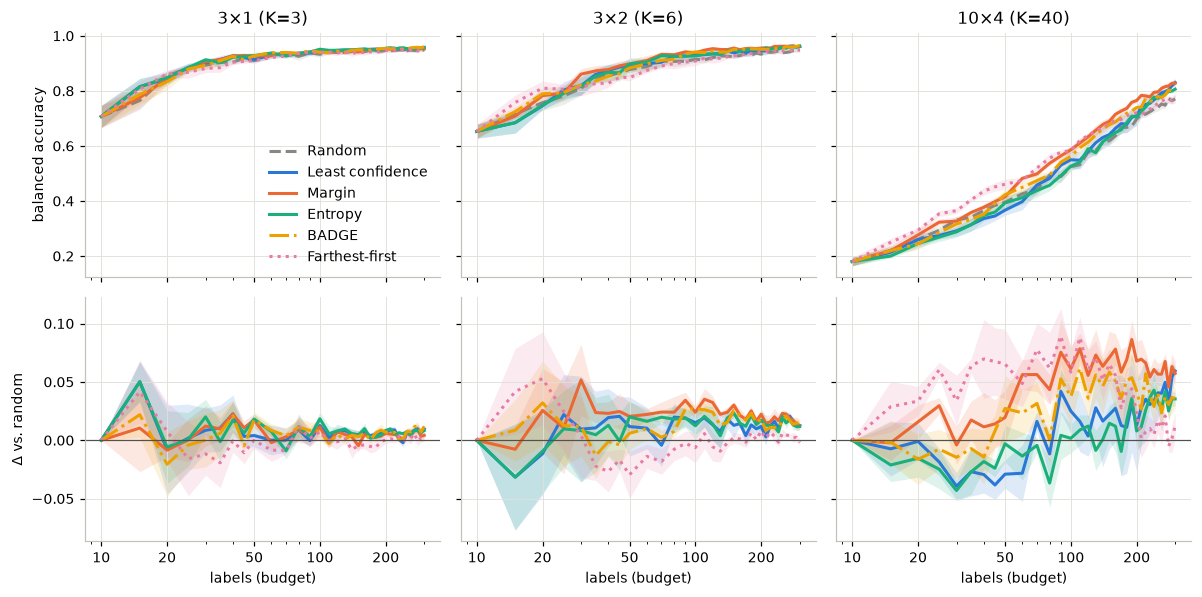

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5), sharex=True, sharey="row")
for j, s in enumerate(REPRESENTATIVE):
    res, x = R[s], R[s]["budgets"]
    for st in STRATEGY_NAMES:
        plot_band(axes[0, j], x, res["acc"][st], **STYLE[st])
        if st != "random":
            plot_band(axes[1, j], x, diff_vs_random(res, st), **STYLE[st])
    axes[1, j].axhline(0, color="#52514e", lw=0.8)
    axes[0, j].set_title(s.label)
    axes[1, j].set_xlabel("labels (budget)")
    log_axis(axes[1, j])
axes[0, 0].set_ylabel("balanced accuracy")
axes[1, 0].set_ylabel("Δ vs. random")
axes[0, 0].legend(loc="lower right")
fig.tight_layout()
savefig(fig, "fig1_learning_curves")
plt.show()

### 6.2 Area under the learning curve (AULC)

AULC is the mean accuracy over a budget range (trapezoid rule, normalised by the width of the range). We report it
separately for the **low** ($\le$ `B_REF` = 100 labels) and **high** (> `B_REF`) regimes, because a single AULC over
the whole range would average the cold-start loss and the later gain into one number. Entries are paired differences
to random, mean ± SE over seeds.

In [15]:
def aulc(budgets, A, lo, hi):
    m = (budgets >= lo) & (budgets <= hi)
    return np.trapezoid(A[:, m], budgets[m], axis=1) / (budgets[m][-1] - budgets[m][0])


def aulc_table(settings, lo, hi):
    others = STRATEGY_NAMES[1:]
    rows = ["| setting | " + " | ".join(STYLE[st]["label"] for st in others) + " |",
            "|---" * (len(others) + 1) + "|"]
    for s in settings:
        res = R[s]
        cells = []
        for st in others:
            m, se = mean_se(aulc(res["budgets"], diff_vs_random(res, st), lo, hi)[:, None])
            cells.append(f"{m[0]:+.3f} ± {se[0]:.3f}")
        rows.append(f"| {s.label} | " + " | ".join(cells) + " |")
    return "\n".join(rows)


display(Markdown(f"**ΔAULC vs. random, low budget ({INIT}–{B_REF} labels)**\n\n" + aulc_table(CORE, 0, B_REF)))
display(Markdown(f"**ΔAULC vs. random, high budget ({B_REF}–{MAX_BUDGET} labels)**\n\n"
                 + aulc_table(CORE, B_REF, MAX_BUDGET)))

**ΔAULC vs. random, low budget (10–100 labels)**

| setting | Least confidence | Margin | Entropy | BADGE | Farthest-first |
|---|---|---|---|---|---|
| 2×1 (K=2) | +0.014 ± 0.004 | +0.014 ± 0.004 | +0.014 ± 0.004 | +0.012 ± 0.005 | +0.002 ± 0.004 |
| 2×2 (K=4) | +0.038 ± 0.006 | +0.038 ± 0.006 | +0.038 ± 0.006 | +0.025 ± 0.008 | +0.028 ± 0.011 |
| 2×4 (K=8) | +0.029 ± 0.014 | +0.029 ± 0.014 | +0.029 ± 0.014 | +0.009 ± 0.007 | -0.010 ± 0.012 |
| 2×8 (K=16) | +0.017 ± 0.011 | +0.017 ± 0.011 | +0.017 ± 0.011 | +0.026 ± 0.007 | +0.005 ± 0.006 |
| 3×1 (K=3) | +0.007 ± 0.008 | +0.007 ± 0.004 | +0.009 ± 0.006 | +0.007 ± 0.006 | -0.000 ± 0.007 |
| 3×2 (K=6) | +0.009 ± 0.016 | +0.023 ± 0.009 | +0.010 ± 0.013 | +0.010 ± 0.008 | -0.004 ± 0.007 |
| 3×4 (K=12) | +0.027 ± 0.017 | +0.042 ± 0.010 | +0.022 ± 0.018 | +0.033 ± 0.012 | +0.045 ± 0.005 |
| 3×8 (K=24) | -0.011 ± 0.017 | +0.017 ± 0.010 | -0.015 ± 0.020 | +0.009 ± 0.010 | +0.023 ± 0.003 |
| 5×1 (K=5) | +0.011 ± 0.011 | +0.021 ± 0.012 | +0.013 ± 0.012 | +0.004 ± 0.005 | +0.014 ± 0.008 |
| 5×2 (K=10) | +0.004 ± 0.013 | +0.035 ± 0.007 | -0.018 ± 0.008 | -0.003 ± 0.015 | +0.008 ± 0.007 |
| 5×4 (K=20) | -0.016 ± 0.017 | +0.040 ± 0.010 | -0.019 ± 0.013 | +0.011 ± 0.014 | +0.021 ± 0.014 |
| 5×8 (K=40) | -0.004 ± 0.018 | +0.016 ± 0.016 | -0.029 ± 0.006 | -0.001 ± 0.016 | +0.035 ± 0.012 |
| 10×1 (K=10) | +0.018 ± 0.014 | +0.038 ± 0.021 | +0.008 ± 0.013 | +0.028 ± 0.013 | +0.047 ± 0.014 |
| 10×2 (K=20) | +0.017 ± 0.005 | +0.060 ± 0.012 | +0.015 ± 0.017 | +0.048 ± 0.010 | +0.050 ± 0.011 |
| 10×4 (K=40) | -0.008 ± 0.010 | +0.035 ± 0.010 | -0.015 ± 0.008 | +0.013 ± 0.016 | +0.059 ± 0.018 |
| 10×8 (K=80) | -0.001 ± 0.005 | +0.008 ± 0.010 | -0.014 ± 0.012 | -0.005 ± 0.006 | +0.040 ± 0.009 |

**ΔAULC vs. random, high budget (100–300 labels)**

| setting | Least confidence | Margin | Entropy | BADGE | Farthest-first |
|---|---|---|---|---|---|
| 2×1 (K=2) | +0.006 ± 0.001 | +0.006 ± 0.001 | +0.006 ± 0.001 | +0.008 ± 0.002 | +0.003 ± 0.002 |
| 2×2 (K=4) | +0.012 ± 0.002 | +0.012 ± 0.002 | +0.012 ± 0.002 | +0.011 ± 0.001 | +0.002 ± 0.002 |
| 2×4 (K=8) | +0.032 ± 0.005 | +0.032 ± 0.005 | +0.032 ± 0.005 | +0.020 ± 0.004 | -0.005 ± 0.006 |
| 2×8 (K=16) | +0.041 ± 0.007 | +0.041 ± 0.007 | +0.041 ± 0.007 | +0.031 ± 0.005 | +0.008 ± 0.004 |
| 3×1 (K=3) | +0.006 ± 0.001 | +0.004 ± 0.001 | +0.007 ± 0.001 | +0.006 ± 0.002 | -0.001 ± 0.002 |
| 3×2 (K=6) | +0.013 ± 0.004 | +0.021 ± 0.002 | +0.015 ± 0.003 | +0.017 ± 0.002 | +0.002 ± 0.002 |
| 3×4 (K=12) | +0.022 ± 0.013 | +0.038 ± 0.005 | +0.028 ± 0.010 | +0.017 ± 0.003 | -0.002 ± 0.006 |
| 3×8 (K=24) | +0.024 ± 0.010 | +0.044 ± 0.006 | +0.024 ± 0.006 | +0.011 ± 0.012 | -0.020 ± 0.008 |
| 5×1 (K=5) | +0.006 ± 0.004 | +0.007 ± 0.004 | +0.005 ± 0.003 | +0.006 ± 0.003 | -0.004 ± 0.004 |
| 5×2 (K=10) | +0.031 ± 0.005 | +0.030 ± 0.004 | +0.025 ± 0.005 | +0.023 ± 0.002 | +0.008 ± 0.004 |
| 5×4 (K=20) | +0.021 ± 0.009 | +0.051 ± 0.009 | +0.011 ± 0.013 | +0.021 ± 0.007 | -0.003 ± 0.010 |
| 5×8 (K=40) | +0.023 ± 0.003 | +0.052 ± 0.012 | +0.013 ± 0.007 | +0.007 ± 0.003 | +0.023 ± 0.004 |
| 10×1 (K=10) | +0.015 ± 0.006 | +0.017 ± 0.003 | +0.007 ± 0.007 | +0.012 ± 0.003 | +0.010 ± 0.003 |
| 10×2 (K=20) | +0.041 ± 0.009 | +0.061 ± 0.005 | +0.028 ± 0.007 | +0.030 ± 0.006 | +0.011 ± 0.003 |
| 10×4 (K=40) | +0.028 ± 0.023 | +0.065 ± 0.010 | +0.019 ± 0.009 | +0.042 ± 0.014 | +0.032 ± 0.011 |
| 10×8 (K=80) | +0.008 ± 0.009 | +0.027 ± 0.015 | -0.005 ± 0.011 | -0.010 ± 0.008 | +0.029 ± 0.011 |

### 6.3 Crossover budget $b^*$

**Definition.** For an uncertainty score $u$, let $\Delta(b)$ be the mean over seeds of the paired difference
$\text{acc}_u(b) - \text{acc}_\text{random}(b)$. Then $b^*$ is the **first budget from which $\Delta$ stays positive
up to the maximum budget**.

* The initial budget itself is skipped: all strategies share the initial set there, so $\Delta = 0$ by construction.
* If $\Delta > 0$ at every later budget, $b^*$ is the first budget after the initial set (no cold start).
* If $\Delta \le 0$ at the last budget, the crossover never happened: $b^* = \infty$, reported as "> max".

**Uncertainty.** We bootstrap over seeds (resampling whole seeds, so the pairing is kept) and recompute $b^*$ on each
resample. CIs are percentile intervals; because $b^*$ can be $\infty$, we use the non-interpolating `inverted_cdf`
quantile.

In [16]:
def crossover_budget(diff, budgets):
    # the initial budget is skipped: all strategies share the initial set, so the difference there is exactly 0
    diff, budgets = diff[:, 1:], budgets[1:]
    pos = diff.mean(0) > 0
    not_pos = np.flatnonzero(~pos)
    if len(not_pos) == 0:
        return float(budgets[0])
    if not_pos[-1] == len(pos) - 1:
        return np.inf
    return float(budgets[not_pos[-1] + 1])


def bootstrap_crossover(diff, budgets, n_boot=CFG["n_boot"], seed=0):
    rng = np.random.default_rng(seed)
    n = len(diff)
    return np.array([crossover_budget(diff[rng.integers(0, n, n)], budgets) for _ in range(n_boot)])


def crossover_summary(s, strategy):
    res, x = R[s], R[s]["budgets"]
    diff = diff_vs_random(res, strategy)
    b_star = crossover_budget(diff, x)
    boot = bootstrap_crossover(diff, x)
    lo, hi = np.quantile(boot, [0.025, 0.975], method="inverted_cdf")
    return dict(b_star=b_star, lo=lo, hi=hi, p_never=np.mean(np.isinf(boot)))


def fmt_b(b):
    return "> max" if np.isinf(b) else f"{b:.0f}"


XO = {(s, st): crossover_summary(s, st) for s in dict.fromkeys(ALL_SETTINGS) for st in UNCERTAINTY}

def fmt_ci(o):
    return f"{fmt_b(o['b_star'])} [{fmt_b(o['lo'])}, {fmt_b(o['hi'])}]"


rows = ["| setting | K | " + " | ".join(f"{STYLE[st]['label']} $b^*$ [95% CI]" for st in UNCERTAINTY) + " |",
        "|---" * 5 + "|"]
for s in CORE:
    rows.append(f"| {s.label} | {s.K} | " + " | ".join(fmt_ci(XO[s, st]) for st in UNCERTAINTY) + " |")
display(Markdown("\n".join(rows)))

| setting | K | Least confidence $b^*$ [95% CI] | Margin $b^*$ [95% CI] | Entropy $b^*$ [95% CI] |
|---|---|---|---|---|
| 2×1 (K=2) | 2 | 230 [15, 270] | 230 [15, 270] | 230 [15, 270] |
| 2×2 (K=4) | 4 | 15 [15, 180] | 15 [15, 180] | 15 [15, 180] |
| 2×4 (K=8) | 8 | 30 [15, 50] | 30 [15, 50] | 30 [15, 50] |
| 2×8 (K=16) | 16 | 45 [15, 110] | 45 [15, 110] | 45 [15, 110] |
| 3×1 (K=3) | 3 | 250 [30, 270] | 160 [100, 300] | 80 [40, 270] |
| 3×2 (K=6) | 6 | 80 [15, 220] | 20 [15, 60] | 50 [15, 250] |
| 3×4 (K=12) | 12 | 25 [15, 270] | 40 [20, 45] | 20 [15, 190] |
| 3×8 (K=24) | 24 | 110 [45, 170] | 50 [25, 170] | 130 [45, 200] |
| 5×1 (K=5) | 5 | 140 [40, 290] | 15 [15, > max] | 190 [40, > max] |
| 5×2 (K=10) | 10 | 45 [25, 70] | 30 [15, 35] | 90 [40, 120] |
| 5×4 (K=20) | 20 | 130 [110, 220] | 15 [15, 80] | 130 [110, 260] |
| 5×8 (K=40) | 40 | 110 [35, 220] | 35 [15, 170] | 180 [120, 220] |
| 10×1 (K=10) | 10 | 40 [25, 290] | 20 [15, 170] | 150 [45, 290] |
| 10×2 (K=20) | 20 | 40 [35, 160] | 20 [15, 35] | 45 [15, 270] |
| 10×4 (K=40) | 40 | 90 [60, 260] | 35 [20, 60] | 180 [70, 270] |
| 10×8 (K=80) | 80 | 180 [140, 270] | 110 [15, 270] | 270 [270, > max] |

### 6.4 Phase diagram

Each row is one core-grid setting (sorted by $K$), each column a budget. Colour is the mean paired difference
**margin − random**: red means margin is worse than random, blue means it is better. Black dots mark $b^*$; a
triangle at the right edge means no crossover within the budget. If H1 and H2 hold, the red region should form a
band at small budgets whose width grows with $K$.

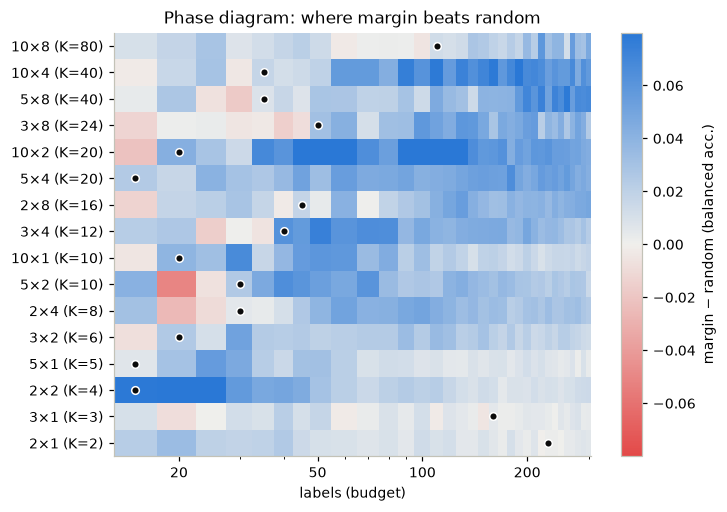

In [17]:
def budget_edges(x):
    # cell edges for pcolormesh on a log axis: geometric midpoints between budgets
    mid = np.sqrt(x[1:] * x[:-1])
    return np.concatenate([[x[0] ** 2 / mid[0]], mid, [x[-1] ** 2 / mid[-1]]])


def phase_diagram(ax, settings, strategy="margin"):
    settings = sorted(settings, key=lambda s: (s.K, s.C))
    x = R[settings[0]]["budgets"][1:]  # drop the initial budget (difference is 0 by construction)
    Z = np.array([diff_vs_random(R[s], strategy).mean(0)[1:] for s in settings])
    vmax = np.quantile(np.abs(Z), 0.98)
    mesh = ax.pcolormesh(budget_edges(x), np.arange(len(settings) + 1), Z, cmap=DIVERGING, vmin=-vmax, vmax=vmax)
    for i, s in enumerate(settings):
        b = XO[s, strategy]["b_star"]
        if np.isfinite(b):
            ax.plot(b, i + 0.5, "o", color="#0b0b0b", ms=5, mec="white", mew=1)
        else:
            ax.plot(x[-1], i + 0.5, ">", color="#0b0b0b", ms=6, mec="white", mew=1)
    log_axis(ax)
    ax.set_yticks(np.arange(len(settings)) + 0.5, [s.label for s in settings])
    ax.set_xlabel("labels (budget)")
    ax.grid(False)
    return mesh


fig, ax = plt.subplots(figsize=(7, 5))
mesh = phase_diagram(ax, CORE)
fig.colorbar(mesh, ax=ax, label="margin − random (balanced acc.)")
ax.set_title("Phase diagram: where margin beats random")
savefig(fig, "fig2_phase_diagram")
plt.show()

Same diagram for the other two uncertainty scores, for completeness (they should look very similar; for $C = 2$ the
three scores are identical, see §6.8).

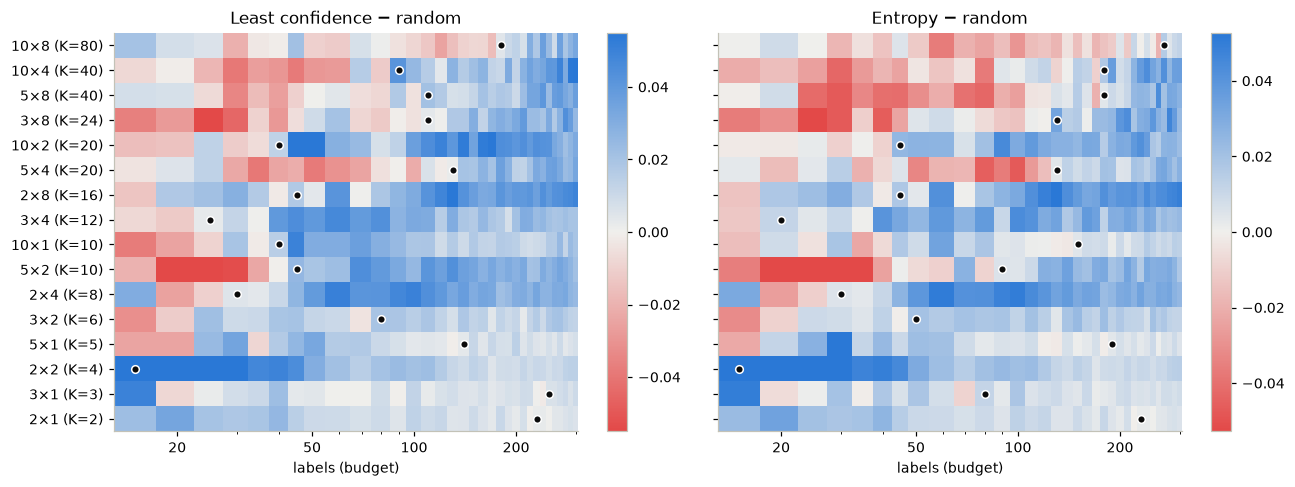

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, st in zip(axes, ["least_conf", "entropy"]):
    mesh = phase_diagram(ax, CORE, st)
    ax.set_title(f"{STYLE[st]['label']} − random")
    fig.colorbar(mesh, ax=ax)
fig.tight_layout()
plt.show()

### 6.6 Best strategy per (setting, budget)

For every core setting and budget, the strategy with the highest mean balanced accuracy (the initial budget is left
out, since all strategies share the initial set there).

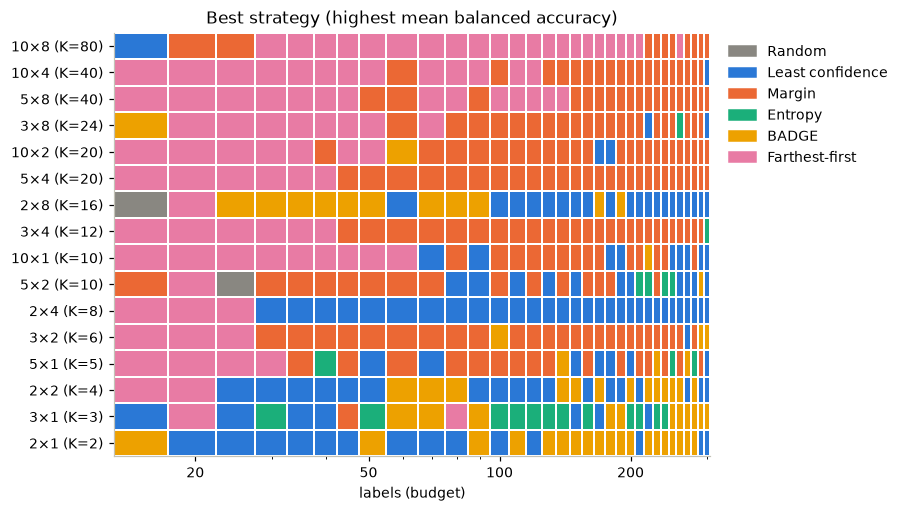

| strategy | share of cells won, ≤ 100 labels | share of cells won, > 100 labels |
|---|---|---|
| Random | 1% | 0% |
| Least confidence | 20% | 26% |
| Margin | 27% | 50% |
| Entropy | 2% | 5% |
| BADGE | 10% | 13% |
| Farthest-first | 40% | 6% |

In [20]:
settings_sorted = sorted(CORE, key=lambda s: (s.K, s.C))
x = R[CORE[0]]["budgets"][1:]  # the initial budget is a tie between all strategies, so it is left out
MEAN = np.array([[R[s]["acc"][st].mean(0)[1:] for st in STRATEGY_NAMES] for s in settings_sorted])  # (setting, strat, B)
best = MEAN.argmax(1)

fig, ax = plt.subplots(figsize=(7, 5))
cmap = ListedColormap([STYLE[st]["color"] for st in STRATEGY_NAMES])
ax.pcolormesh(budget_edges(x), np.arange(len(settings_sorted) + 1), best, cmap=cmap,
              vmin=-0.5, vmax=len(STRATEGY_NAMES) - 0.5, edgecolors="white", linewidth=0.3)
log_axis(ax)
ax.set_yticks(np.arange(len(settings_sorted)) + 0.5, [s.label for s in settings_sorted])
ax.set_xlabel("labels (budget)")
ax.grid(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=STYLE[st]["color"]) for st in STRATEGY_NAMES]
ax.legend(handles, [STYLE[st]["label"] for st in STRATEGY_NAMES], loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Best strategy (highest mean balanced accuracy)")
savefig(fig, "fig4_best_strategy_map")
plt.show()

low, high = x <= B_REF, x > B_REF
WINS = {st: ((best[:, low] == j).mean(), (best[:, high] == j).mean()) for j, st in enumerate(STRATEGY_NAMES)}
display(Markdown(f"| strategy | share of cells won, ≤ {B_REF} labels | share of cells won, > {B_REF} labels |\n"
                 "|---|---|---|\n" + "\n".join(
                     f"| {STYLE[st]['label']} | {lo_:.0%} | {hi_:.0%} |" for st, (lo_, hi_) in WINS.items())))

Note: for $C = 2$ least confidence, margin and entropy produce the same queries, so in those rows a "win" by one of
them is effectively a win by all three (`argmax` just reports the first).

### 6.7 Separation and class-imbalance sweeps

Each panel varies one factor around the reference setting (3 classes × 2 modes, d = 10, separation 4σ, balanced) and
shows **margin − random** (mean ± SE), darker = larger value of the factor. The table below gives $b^*$ for each
level and each uncertainty score.

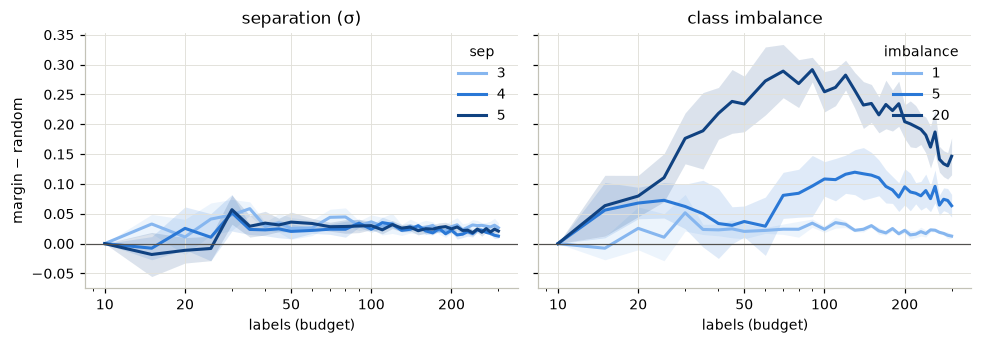

| factor | value | Least confidence $b^*$ [95% CI] | Margin $b^*$ [95% CI] | Entropy $b^*$ [95% CI] |
|---|---|---|---|---|
| separation (σ) | 3 | 15 [15, > max] | 15 [15, 130] | 45 [15, 150] |
| separation (σ) | 4 | 80 [15, 220] | 20 [15, 60] | 50 [15, 250] |
| separation (σ) | 5 | 20 [20, 50] | 30 [20, 30] | 20 [20, 90] |
| class imbalance | 1 | 80 [15, 220] | 20 [15, 60] | 50 [15, 250] |
| class imbalance | 5 | 15 [15, 50] | 15 [15, 70] | 15 [15, 70] |
| class imbalance | 20 | 15 [15, 15] | 15 [15, 20] | 15 [15, 15] |

In [21]:
fig, axes = plt.subplots(1, len(SWEEPS), figsize=(9, 3.2), sharey=True)
rows = ["| factor | value | " + " | ".join(f"{STYLE[st]['label']} $b^*$ [95% CI]" for st in UNCERTAINTY) + " |",
        "|---" * 5 + "|"]
for ax, (title, (field, settings)) in zip(axes, SWEEPS.items()):
    for color, s in zip(SWEEP_COLORS, settings):
        v = getattr(s, field)
        plot_band(ax, R[s]["budgets"], diff_vs_random(R[s], "margin"), color=color, label=f"{v:g}")
        rows.append(f"| {title} | {v:g} | " + " | ".join(fmt_ci(XO[s, st]) for st in UNCERTAINTY) + " |")
    ax.axhline(0, color="#52514e", lw=0.8)
    log_axis(ax)
    ax.set_title(title)
    ax.set_xlabel("labels (budget)")
    ax.legend(title=field, loc="upper right")
axes[0].set_ylabel("margin − random")
fig.tight_layout()
savefig(fig, "sweeps")
plt.show()
display(Markdown("\n".join(rows)))

### 6.8 Sanity check: the binary case

For $C = 2$, least confidence ($1 - p_1$), margin ($2p_1 - 1$) and entropy ($H(p_1)$) are all monotone in the top
probability $p_1$, so they rank the pool identically. Because they also share the tie-breaking random stream, their
learning curves should (nearly) coincide. A large difference here would point to a bug.

In [22]:
for s in [s for s in CORE if s.C == 2]:
    a = R[s]["acc"]
    d1 = np.abs(a["least_conf"] - a["margin"]).max()
    d2 = np.abs(a["entropy"] - a["margin"]).max()
    print(f"{s.label:14s} max |LC − margin| = {d1:.4f}   max |entropy − margin| = {d2:.4f}")

2×1 (K=2)      max |LC − margin| = 0.0000   max |entropy − margin| = 0.0000
2×2 (K=4)      max |LC − margin| = 0.0000   max |entropy − margin| = 0.0000
2×4 (K=8)      max |LC − margin| = 0.0000   max |entropy − margin| = 0.0000
2×8 (K=16)     max |LC − margin| = 0.0000   max |entropy − margin| = 0.0000


## 7. Summary

The cell below collects the headline numbers in one place, to make writing the report easier:

* **H1:** in how many core settings each uncertainty score has a crossover within the budget, and whether there is a
  cold start at all ($b^*$ later than the first query batch).
* **H2:** slope of log $b^*$ against log $K$ (from §6.5).
* **Sweeps:** margin's $b^*$ at each level of separation and class imbalance (from §6.7).
* **Practical:** which strategy is most often best at low and at high budgets (from §6.6).

In [23]:
first = budget_schedule(MAX_BUDGET)[1]
lines = ["**H1: crossover and cold start (core grid)**", ""]
for st in UNCERTAINTY:
    b = np.array([XO[s, st]["b_star"] for s in CORE])
    lines.append(f"- {STYLE[st]['label']}: crossover within budget in {np.isfinite(b).sum()}/{len(CORE)} settings; "
                 f"cold start (b* later than the first query batch) in {(b > first).sum()}/{len(CORE)}; "
                 f"median b* = {fmt_b(np.median(b))}")

lines += ["", "**H2: slope of log b* vs. log K**", ""]
lines += [f"- {STYLE[st]['label']}: {slope:+.2f}" for st, slope in SLOPES.items()]

lines += ["", "**Sweeps: margin b* per level**", ""]
for title, (field, settings) in SWEEPS.items():
    lines.append(f"- {title}: " + ", ".join(f"{getattr(s, field):g} → {fmt_b(XO[s, 'margin']['b_star'])}"
                                           for s in settings))

lines += ["", "**Best strategy (share of core-grid cells won)**", ""]
for label, k in ((f"≤ {B_REF} labels", 0), (f"> {B_REF} labels", 1)):
    top = max(WINS, key=lambda st: WINS[st][k])
    lines.append(f"- {label}: {STYLE[top]['label']} ({WINS[top][k]:.0%} of cells)")

lines += ["", f"_Mode: `{MODE}` ({len(SEEDS)} seeds, budget ≤ {MAX_BUDGET})._ "
          + ("Re-run with `MODE = \"full\"` for the report numbers." if MODE == "quick" else "")]
display(Markdown("\n".join(lines)))

**H1: crossover and cold start (core grid)**

- Least confidence: crossover within budget in 16/16 settings; cold start (b* later than the first query batch) in 15/16; median b* = 85
- Margin: crossover within budget in 16/16 settings; cold start (b* later than the first query batch) in 13/16; median b* = 32
- Entropy: crossover within budget in 16/16 settings; cold start (b* later than the first query batch) in 15/16; median b* = 110

**H2: slope of log b* vs. log K**

- Least confidence: +0.03
- Margin: -0.09
- Entropy: +0.27

**Sweeps: margin b* per level**

- separation (σ): 3 → 15, 4 → 20, 5 → 30
- class imbalance: 1 → 20, 5 → 15, 20 → 15

**Best strategy (share of core-grid cells won)**

- ≤ 100 labels: Farthest-first (40% of cells)
- > 100 labels: Margin (50% of cells)

_Mode: `quick` (5 seeds, budget ≤ 300)._ Re-run with `MODE = "full"` for the report numbers.

### Caveats and possible extensions

* $b^*$ is defined on the *mean* difference; at high budgets all strategies approach the ceiling and $\Delta$ can hover
  around zero, which can push $b^*$ late or to "> max". The bootstrap CI and the probability of no crossover make
  this visible; if it becomes a problem, a small tolerance (e.g. $\Delta > -0.005$) is a reasonable variant to report.
* Difficulty is controlled through the *closest* pair of modes; at $K = 40$–$80$ there are more near neighbours and
  the ceiling drops a little (§2). It is worth stating this when interpreting the largest-$K$ rows.
* The generator also supports other dimensions (`d`), unequal mode sizes (`mode_skew`) and label noise
  (`label_noise`), which are not used in the sweeps above. Adding one is a single line in `SWEEPS`.